# DBSCAN — Manhattan


In [ ]:
import time
import tracemalloc
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler, Normalizer

default_data = next(
    (path for path in (Path("data/cafes.csv"), Path("cafes.csv")) if path.is_file()),
    Path("data/cafes.csv"),
)
DATA_PATH = Path(globals().get("DATA_PATH", default_data)).expanduser().resolve()
FIGURES_DIR = Path(globals().get("FIGURES_DIR", Path("reports/figures"))).expanduser().resolve()
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"CSV tidak ditemukan: {DATA_PATH}. Buka notebook dari folder paket "
        "atau tentukan DATA_PATH ke lokasi CSV Anda."
    )
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
# ==============================================================================
# BAGIAN A: LOAD DATA & PREPROCESSING
# ==============================================================================
print("\n" + "="*56)
print("  BAGIAN A: LOAD DATA & PREPROCESSING (DBSCAN)")
print("="*56)

df = pd.read_csv(DATA_PATH, on_bad_lines="skip")
kolom_fitur = ['latitude', 'longitude', 'rating', 'review_count']
kolom_ada = [k for k in kolom_fitur if k in df.columns]
df_fitur = df[kolom_ada].dropna()

# Standardisasi fitur numerik
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_fitur)

print(f"Data siap | Shape: {X_scaled.shape} | Baris: {len(df_fitur)}")



  BAGIAN A: LOAD DATA & PREPROCESSING (DBSCAN)
Data siap | Shape: (215, 4) | Baris: 215



  BAGIAN B: K-DISTANCE GRAPH (KNN UNTUK TUNING EPS)


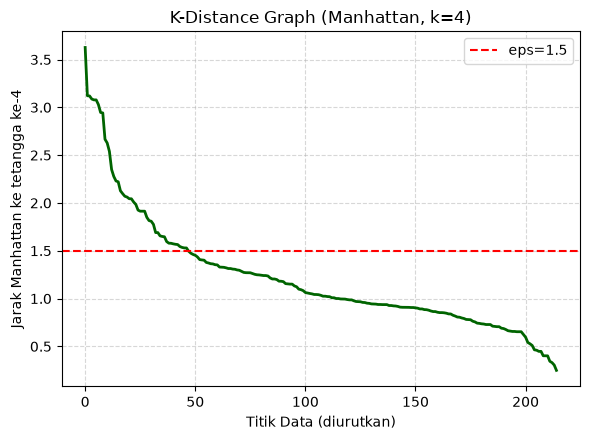

K-distance graph disimpan: E:\Code\machine_learning\uts\reports\figures\dbscan_manhattan_kdistance_plots.png


In [3]:
# ==============================================================================
# BAGIAN B: K-DISTANCE GRAPH (UNTUK MENENTUKAN EPSILON OPTIMAL)
# ==============================================================================
print("\n" + "="*56)
print("  BAGIAN B: K-DISTANCE GRAPH (KNN UNTUK TUNING EPS)")
print("="*56)

# Nilai min_samples acuan untuk estimasi eps
K_NEIGHBORS = 4

# 2. K-Distance Manhattan
nn_m = NearestNeighbors(n_neighbors=K_NEIGHBORS, metric='manhattan').fit(X_scaled)
d_m, _ = nn_m.kneighbors(X_scaled)
kdist_m = np.sort(d_m[:, -1])[::-1]
EPS_MANH = 1.5

plt.figure(figsize=(6, 4.5))
plt.plot(kdist_m, color='darkgreen', linewidth=2)
plt.axhline(y=EPS_MANH, color='red', linestyle='--', linewidth=1.5, label=f'eps={EPS_MANH}')
plt.title(f'K-Distance Graph (Manhattan, k={K_NEIGHBORS})')
plt.xlabel('Titik Data (diurutkan)')
plt.ylabel(f'Jarak Manhattan ke tetangga ke-{K_NEIGHBORS}')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
kdist_plot_path = FIGURES_DIR / "dbscan_manhattan_kdistance_plots.png"
plt.savefig(kdist_plot_path, dpi=150)
plt.show()
plt.close()
print(f"K-distance graph disimpan: {kdist_plot_path}")


In [4]:
# --- 2. DBSCAN MANHATTAN ---
print("\n" + "="*56)
print("  DBSCAN — METRIK: MANHATTAN")
print(f"  Parameter: eps={EPS_MANH}, min_samples={K_NEIGHBORS}")
print("="*56)

tracemalloc.start()
t_mulai = time.time()

db_manhattan = DBSCAN(eps=EPS_MANH, min_samples=K_NEIGHBORS, metric='manhattan')
lbl_manhattan = db_manhattan.fit_predict(X_scaled)

t_selesai = time.time()
_, mem_puncak = tracemalloc.get_traced_memory()
tracemalloc.stop()

n_klaster_m = len(set(lbl_manhattan)) - (1 if -1 in lbl_manhattan else 0)
n_noise_m = int((lbl_manhattan == -1).sum())
pct_noise_m = n_noise_m / len(lbl_manhattan) * 100
mask_valid_m = lbl_manhattan != -1

if mask_valid_m.sum() > 1 and n_klaster_m >= 2:
    sil_manhattan = silhouette_score(X_scaled[mask_valid_m], lbl_manhattan[mask_valid_m], metric='manhattan')
    sil_m_str = f"{sil_manhattan:.4f}"
else:
    sil_manhattan = None
    sil_m_str = "N/A (klaster < 2)"

waktu_m = t_selesai - t_mulai
mem_m_kb = mem_puncak / 1024
mem_m_mb = mem_puncak / (1024**2)

print(f"  Jumlah Klaster    : {n_klaster_m}")
print(f"  Titik Noise (-1)  : {n_noise_m} ({pct_noise_m:.1f}%)")
print(f"  Waktu Eksekusi    : {waktu_m:.4f} detik")
print(f"  Memori Puncak     : {mem_m_kb:.2f} KB ({mem_m_mb:.4f} MB)")
print(f"  Silhouette Score  : {sil_m_str}")
print("="*56)



  DBSCAN — METRIK: MANHATTAN
  Parameter: eps=1.5, min_samples=4
  Jumlah Klaster    : 1
  Titik Noise (-1)  : 34 (15.8%)
  Waktu Eksekusi    : 0.0120 detik
  Memori Puncak     : 229.85 KB (0.2245 MB)
  Silhouette Score  : N/A (klaster < 2)



  BAGIAN D: VISUALISASI PCA 2D (DBSCAN)


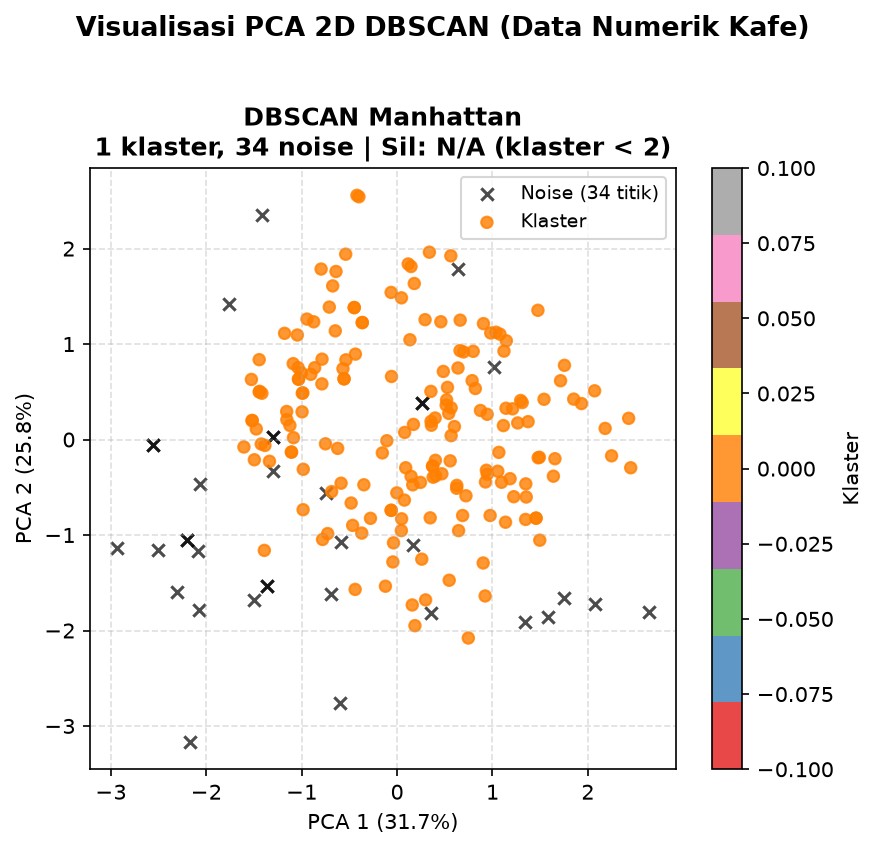

Visualisasi PCA disimpan ke: E:\Code\machine_learning\uts\reports\figures\dbscan_manhattan_pca_plots.png


In [ ]:
# ==============================================================================
# BAGIAN D: VISUALISASI PCA 2D DENGAN TITIK NOISE HITAM (X)
# ==============================================================================
print("\n" + "="*56)
print("  BAGIAN D: VISUALISASI PCA 2D (DBSCAN)")
print("="*56)

pca = PCA(n_components=2, random_state=42)
X_pca_std = pca.fit_transform(X_scaled)
v1_std, v2_std = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(6, 5.5), dpi=150)
axes = [ax]

def plot_dbscan_pca(ax, X_pca_coords, lbls, v1, v2, title):
    mask_noise = lbls == -1
    mask_klaster = ~mask_noise

    # Plot titik noise -> hitam, tanda x
    ax.scatter(X_pca_coords[mask_noise, 0], X_pca_coords[mask_noise, 1],
               c='black', marker='x', s=35, alpha=0.7,
               label=f'Noise ({mask_noise.sum()} titik)')

    # Plot titik klaster -> berwarna
    if mask_klaster.sum() > 0:
        sc = ax.scatter(X_pca_coords[mask_klaster, 0], X_pca_coords[mask_klaster, 1],
                        c=lbls[mask_klaster], cmap='Set1', s=30, alpha=0.8,
                        label='Klaster')
        plt.colorbar(sc, ax=ax, label='Klaster')

    ax.set_title(title, fontweight='bold')
    ax.set_xlabel(f'PCA 1 ({v1:.1f}%)')
    ax.set_ylabel(f'PCA 2 ({v2:.1f}%)')
    ax.legend(fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.4)

plot_dbscan_pca(axes[0], X_pca_std, lbl_manhattan, v1_std, v2_std,
                f"DBSCAN Manhattan\n{n_klaster_m} klaster, {n_noise_m} noise | Sil: {sil_m_str}")

plt.suptitle("Visualisasi PCA 2D DBSCAN (Data Numerik Kafe)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
dbscan_pca_path = FIGURES_DIR / "dbscan_manhattan_pca_plots.png"
plt.savefig(dbscan_pca_path, dpi=150, bbox_inches='tight')
plt.show()
plt.close()
print(f"Visualisasi PCA disimpan ke: {dbscan_pca_path}")


In [6]:
# Dictionary ringkasan performa untuk pelaporan
DBSCAN_SUMMARY = {
    "manhattan": {
        "algo": "DBSCAN", "metric": "Manhattan", "param": f"eps={EPS_MANH}, ms={K_NEIGHBORS}",
        "time": waktu_m, "mem_mb": mem_m_mb, "clusters": n_klaster_m,
        "noise_pct": pct_noise_m, "silhouette": sil_manhattan, "labels": lbl_manhattan
    }
}
